## Run initial SUMMA model tests ##

In [1]:
from pathlib import Path

# add auto reload for jupyter magic
%load_ext autoreload
%autoreload 2

In [1]:
from pathlib import Path

from snowda.workflows.run_pysummada_pf import run_pysummada_pf

config_path = Path("../runs/examples/ross_summa_deterministic.yaml")
run_dir = run_pysummada_pf(config_path)

print("ESP run directory:", run_dir)

2026-02-18 13:05:52 | INFO     | snowda.snowda.workflows.run_pysummada_pf | snowda pysummada PF run starting
2026-02-18 13:05:52 | INFO     | snowda.snowda.workflows.run_pysummada_pf | Config: ../runs/examples/ross_summa_deterministic.yaml
2026-02-18 13:05:52 | INFO     | snowda.snowda.workflows.run_pysummada_pf | Run dir: /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260218T200552Z
2026-02-18 13:05:52 | INFO     | snowda.snowda.workflows.run_pysummada_pf | Wrote config snapshot: /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260218T200552Z/config.resolved.json
2026-02-18 13:05:52 | INFO     | snowda.snowda.io.summa_ensemble | Creating output directories
2026-02-18 13:05:52 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/SUMMA
2026-02-18 13:05:52 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/

CalledProcessError: Command '['/Users/dcasson/GitHub/mizuRoute/route/bin/route_runoff.exe', '/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20260218T200552Z/mizuroute/mizuroute_deterministic.control']' returned non-zero exit status 30.

In [6]:
# Option B: Run SUMMA fSCA workflow (requires existing SUMMA outputs)
from snowda.workflows.run_summa_fsca import run_summa_fsca


config_path = Path("../runs/examples/chena_summa_fsca.yaml").resolve()
run_dir = run_summa_fsca(config_path)
print("fSCA run dir:", run_dir)

2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | snowda fSCA run starting
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Config: /Users/dcasson/GitHub/snowda/runs/examples/chena_summa_fsca.yaml
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Run dir: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z
2026-01-19 14:23:40 | INFO     | snowda.snowda.workflows.run_summa_fsca | Wrote config snapshot: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z/config.resolved.yaml
2026-01-19 14:23:40 | INFO     | snowda.snowda.io.summa_fsca | Preparing SUMMA fSCA input from [PosixPath('/Users/dcasson/GitHub/snowda/outputs/chena_summa_minimal/chena_pysumma_run_timestep.nc')]
2026-01-19 14:23:41 | WARNING  | snowda.snowda.io.summa_fsca | Unit conversion failed (unsupported operand type(s) for -: 'ParserHelper' and 'int'). Proceeding without conversions.
2026-01-19 14:23:43 | INFO     | snowda.snowda.io

fSCA run dir: /Users/dcasson/Data/snowda/summa/chena/output/20260119T212340Z


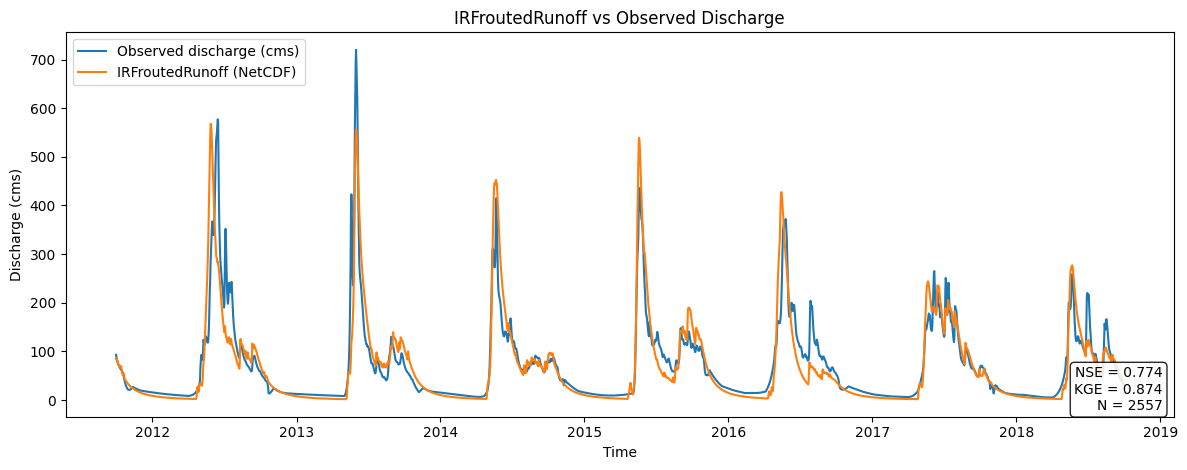

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional, Tuple, Union

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


def nse(sim: np.ndarray, obs: np.ndarray) -> float:
    """Nash–Sutcliffe Efficiency."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    denom = np.sum((obs - np.mean(obs)) ** 2)
    if denom == 0:
        return np.nan
    return 1.0 - np.sum((obs - sim) ** 2) / denom


def kge(sim: np.ndarray, obs: np.ndarray) -> float:
    """Kling–Gupta Efficiency (Gupta et al., 2009)."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    # Pearson r
    if np.std(sim) == 0 or np.std(obs) == 0:
        r = np.nan
    else:
        r = np.corrcoef(sim, obs)[0, 1]

    mu_s, mu_o = np.mean(sim), np.mean(obs)
    sd_s, sd_o = np.std(sim, ddof=1), np.std(obs, ddof=1)

    alpha = sd_s / sd_o if sd_o != 0 else np.nan
    beta = mu_s / mu_o if mu_o != 0 else np.nan

    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan

    return 1.0 - np.sqrt((r - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2)


def plot_irfroutedrunoff_vs_discharge(
    nc_path: str,
    csv_path: str,
    *,
    irf_var: str = "IRFroutedRunoff",
    seg_index: int = 0,
    csv_datetime_col: Optional[str] = None,
    csv_discharge_col: Optional[str] = None,
    # NetCDF is hourly in your example; CSV is daily. Default: daily mean.
    resample_rule: str = "D",
    agg: str = "mean",  # "mean" or "sum"
    timezone: Optional[str] = None,  # e.g., "UTC" if you need to force TZ
    out_png: Optional[str] = None,
    title: Optional[str] = None,
) -> Tuple[plt.Figure, plt.Axes, float, float]:
    """
    Read IRFroutedRunoff from NetCDF and discharge (cms) from CSV, align in time,
    compute NSE + KGE, and plot both series with metrics on the figure.

    Returns: (fig, ax, NSE, KGE)
    """
    # --- Read NetCDF ---
    ds = xr.open_dataset(nc_path)

    if irf_var not in ds:
        raise KeyError(f"Variable '{irf_var}' not found in {nc_path}. Available: {list(ds.data_vars)}")

    da = ds[irf_var]
    # Expect dims like (time, seg). If seg missing, just use as-is.
    if "seg" in da.dims:
        da = da.isel(seg=seg_index)

    # Convert to pandas Series indexed by datetime
    sim = da.to_series()
    sim.index = pd.to_datetime(sim.index)

    if timezone:
        # localize if naive; otherwise convert
        if sim.index.tz is None:
            sim.index = sim.index.tz_localize(timezone)
        else:
            sim.index = sim.index.tz_convert(timezone)

    # Resample NetCDF series to match CSV cadence
    if resample_rule:
        if agg.lower() == "mean":
            sim = sim.resample(resample_rule).mean()
        elif agg.lower() == "sum":
            sim = sim.resample(resample_rule).sum()
        else:
            raise ValueError("agg must be 'mean' or 'sum'")

    # --- Read CSV ---
    df = pd.read_csv(csv_path)

    # Try to infer columns if not provided
    if csv_datetime_col is None:
        for c in ["datetime", "date", "time", "timestamp", "Datetime", "DATE", "Date"]:
            if c in df.columns:
                csv_datetime_col = c
                break
    if csv_discharge_col is None:
        for c in ["discharge_cms", "discharge", "Q", "q", "flow", "streamflow", "Discharge_cms"]:
            if c in df.columns:
                csv_discharge_col = c
                break

    if csv_datetime_col is None or csv_discharge_col is None:
        # Fallback: assume first col is datetime, second is discharge
        if df.shape[1] < 2:
            raise ValueError("CSV must have at least 2 columns (datetime, discharge).")
        csv_datetime_col = df.columns[0]
        csv_discharge_col = df.columns[1]

    obs = df[[csv_datetime_col, csv_discharge_col]].copy()
    obs[csv_datetime_col] = pd.to_datetime(obs[csv_datetime_col])
    obs = obs.set_index(csv_datetime_col).sort_index()
    obs = obs.rename(columns={csv_discharge_col: "discharge_cms"})
    obs = obs["discharge_cms"].astype(float)

    if timezone:
        if obs.index.tz is None:
            obs.index = obs.index.tz_localize(timezone)
        else:
            obs.index = obs.index.tz_convert(timezone)

    # If CSV is not already at the same cadence, resample it too
    if resample_rule:
        # For discharge, daily mean is typical. Keep it consistent with sim.
        if agg.lower() == "mean":
            obs = obs.resample(resample_rule).mean()
        elif agg.lower() == "sum":
            obs = obs.resample(resample_rule).sum()

    # --- Align overlap ---
    aligned = pd.concat([sim.rename("IRF"), obs.rename("OBS")], axis=1).dropna()
    if aligned.empty:
        raise ValueError("No overlapping timestamps after alignment. Check time ranges / timezone / resampling.")

    sim_a = aligned["IRF"].to_numpy()
    obs_a = aligned["OBS"].to_numpy()

    NSE = nse(sim_a, obs_a)
    KGE = kge(sim_a, obs_a)

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(12, 4.8))

    ax.plot(aligned.index, aligned["OBS"], label="Observed discharge (cms)")
    ax.plot(aligned.index, aligned["IRF"], label=f"{irf_var} (NetCDF)")

    ax.set_xlabel("Time")
    ax.set_ylabel("Discharge (cms)")

    if title is None:
        title = f"{irf_var} vs Observed Discharge"
    ax.set_title(title)

    ax.legend(loc="upper left")

    txt = f"NSE = {NSE:.3f}\nKGE = {KGE:.3f}\nN = {len(aligned):d}"
    ax.text(
        0.99,
        0.01,
        txt,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
    )

    fig.tight_layout()

    if out_png:
        fig.savefig(out_png, dpi=200)

    return fig, ax, NSE, KGE


# Example usage with your uploaded files:
fig, ax, NSE, KGE = plot_irfroutedrunoff_vs_discharge(
     "//Users/dcasson/Data/snowda/summa/ross_lumped/output/mizuroute_output/Ross.h.2011-10-01-00000.nc",
     "/Users/dcasson/Data/snowda/summa/ross_lumped/observations/streamflow.csv",
     resample_rule="D",
     agg="mean",
    out_png="/Users/dcasson/Data/snowda/summa/ross_lumped/output/mizuroute_output/Ross.png",
  )
plt.show()